<a href="https://colab.research.google.com/github/harshithnova/indian-currency-condition-classifier/blob/main/currency_condition_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.Setup cell

 Dataset_v2 was created in data_split.ipynb (near-duplicate grouping, label-conflict removal, balanced train). It is not re-created here.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Imports
import os
import tensorflow as tf

# Paths
DATA_DIR = '/content/drive/MyDrive/Dataset_v2'
PROJECT = '/content/drive/MyDrive/CurrencyProject'

# Folders for saved models and results
os.makedirs(f'{PROJECT}/models', exist_ok=True)
os.makedirs(f'{PROJECT}/results', exist_ok=True)

# Check image counts and GPU
for split in ['train', 'val', 'test']:
    for cls in ['Crisp', 'Worn', 'Damaged']:
        print(split, cls, len(os.listdir(f'{DATA_DIR}/{split}/{cls}')))
print(tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train Crisp 256
train Worn 256
train Damaged 256
val Crisp 60
val Worn 60
val Damaged 60
test Crisp 60
test Worn 61
test Damaged 63
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2.Load the data and check the labels

load train, val and test

In [ ]:
# Image size and batch size used for all models
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

# Training data: shuffled so the model sees images in random order
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + '/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=42)

# Validation data: not shuffled, so predictions stay aligned with labels
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + '/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

# Test data: not shuffled, for the same reason
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR + '/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

# Class names come from the folder names, in alphabetical order
class_names = train_ds.class_names
print(class_names)

Found 768 files belonging to 3 classes.
Found 180 files belonging to 3 classes.
Found 184 files belonging to 3 classes.
['Crisp', 'Damaged', 'Worn']


show sample images

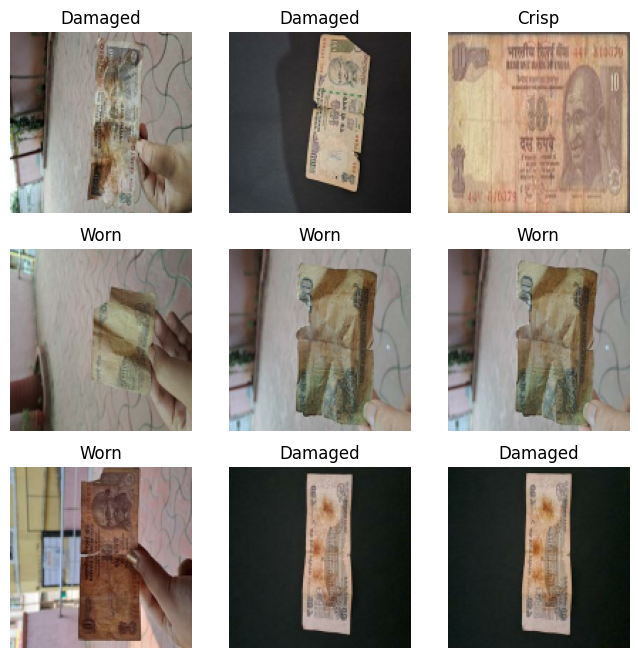

In [ ]:
import matplotlib.pyplot as plt

# Take one batch of 16 training images and show the first 9 with their labels
images, labels = next(iter(train_ds))

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_names[labels[i].numpy().argmax()])
    plt.axis('off')
plt.show()

# 3.Build the custom CNN

imports and a quick check that the datasets still exist

In [ ]:
# Import the layers and models we need from Keras
from tensorflow import keras
from tensorflow.keras import layers

# Check that the datasets from step 2 are still in memory
print(train_ds)
print(val_ds)
print(class_names)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None))>
['Crisp', 'Damaged', 'Worn']


In [ ]:
# Data augmentation: flip, small rotation, brightness, contrast (training only)
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
], name='data_augmentation')

# Where the best custom CNN is saved
best_model_path = PROJECT + '/models/custom_cnn_best.keras'

augmentation and model

In [ ]:
# Data augmentation: only active during training, switched off at test time
model_cnn = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    # Augmentation (training only), then scale pixels to 0-1
    data_augmentation,
    layers.Rescaling(1.0 / 255),

    # Conv block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),

    # Conv block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),

    # Conv block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(momentum=0.9),
    layers.MaxPooling2D(),

    # Classifier head
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax"),
])

# Lower learning rate than before (5e-4 instead of 1e-3)
model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model_cnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,595 (400.76 KB)

 Trainable params: 102,147 (399.01 KB)

 Non-trainable params: 448 (1.75 KB)

# 4.Train the custom CNN

callbacks and training

In [ ]:
# Fresh callbacks: patience is now 8 for EarlyStopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

checkpoint = keras.callbacks.ModelCheckpoint(
    best_model_path, monitor='val_loss', save_best_only=True)

# Train again
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop, reduce_lr, checkpoint],
)

# Print one line per epoch
for i in range(len(history_cnn.history['loss'])):
    print('Epoch', i + 1,
          '| train acc:', round(history_cnn.history['accuracy'][i], 3),
          '| val acc:', round(history_cnn.history['val_accuracy'][i], 3),
          '| val loss:', round(history_cnn.history['val_loss'][i], 3))

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.6393 - loss: 0.7909 - val_accuracy: 0.5333 - val_loss: 1.0275 - learning_rate: 5.0000e-04
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7174 - loss: 0.6102 - val_accuracy: 0.7222 - val_loss: 0.5034 - learning_rate: 5.0000e-04
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7591 - loss: 0.5506 - val_accuracy: 0.7444 - val_loss: 0.4957 - learning_rate: 5.0000e-04
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7617 - loss: 0.5325 - val_accuracy: 0.7889 - val_loss: 0.4592 - learning_rate: 5.0000e-04
Epoch 5/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7578 - loss: 0.4992 - val_accuracy: 0.8222 - val_loss: 0.4081 - learning_rate: 5.0000e-04
Epoch 6/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8008 - loss: 0.4337 - val_accuracy: 0.6111 - val_loss: 0.8010 - learning_rate: 5.0000e-04
Epoch 7/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7943 

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Predict on validation data with the restored best model
val_probs = model_cnn.predict(val_ds)
val_pred = np.argmax(val_probs, axis=1)

# Get true labels (val_ds is not shuffled, so the order matches)
val_true = np.concatenate([np.argmax(y.numpy(), axis=1) for x, y in val_ds])

# Rows = true class, columns = predicted class (Crisp, Damaged, Worn)
print(class_names)
print(confusion_matrix(val_true, val_pred))
print('Val accuracy:', round(np.mean(val_pred == val_true), 3))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
['Crisp', 'Damaged', 'Worn']
[[59  1  0]
 [ 0 56  4]
 [ 0  5 55]]
Val accuracy: 0.944


plot and save the curves

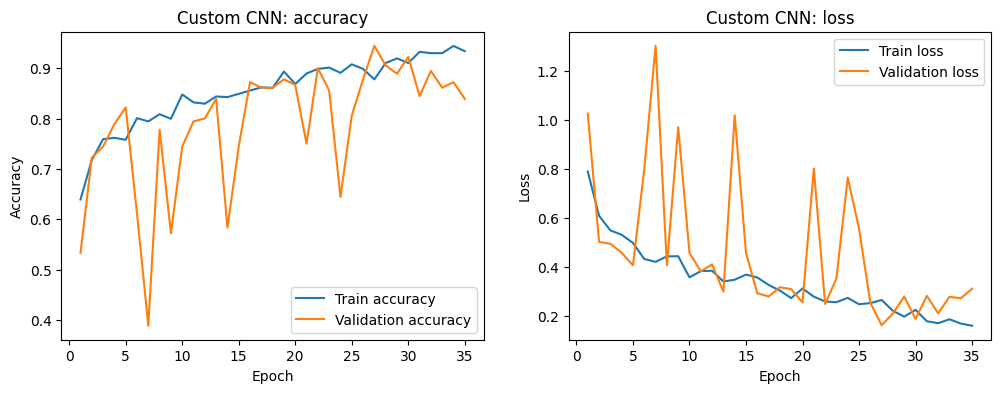

Best epoch (lowest val_loss): 27
Val accuracy at that epoch: 0.9444444179534912


In [ ]:
import matplotlib.pyplot as plt

# Read the training history
train_acc = history_cnn.history['accuracy']
val_acc = history_cnn.history['val_accuracy']
train_loss = history_cnn.history['loss']
val_loss = history_cnn.history['val_loss']
epochs_range = range(1, len(train_acc) + 1)

# Draw accuracy (left) and loss (right) side by side
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_acc, label='Train accuracy')
plt.plot(epochs_range, val_acc, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Custom CNN: accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label='Train loss')
plt.plot(epochs_range, val_loss, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Custom CNN: loss')
plt.legend()

# Save the figure to the results folder, then show it
plt.savefig(PROJECT + '/results/custom_cnn_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Print the best validation accuracy and the epoch where val_loss was lowest
best_epoch = val_loss.index(min(val_loss)) + 1
print('Best epoch (lowest val_loss):', best_epoch)
print('Val accuracy at that epoch:', val_acc[best_epoch - 1])

# 5.MobileNetV2 comparison model

build the model and train only the new head

In [ ]:
# Load MobileNetV2 pretrained on ImageNet, without its original classifier
base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet',
)

# Freeze the pretrained layers so they are not changed in this phase
base_model.trainable = False

# Build the full model with the functional style
inputs = keras.Input(shape=(128, 128, 3))
x = data_augmentation(inputs)

# MobileNetV2 expects pixels in [-1, 1], so scale 0-255 to -1..1
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1)(x)

# Pretrained feature extractor (training=False keeps its BatchNorm in prediction mode)
x = base_model(x, training=False)

# New 3-class head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation='softmax')(x)

model_mob = keras.Model(inputs, outputs)

# Compile with a normal learning rate because only the head is training
model_mob.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

# Stop early if val_loss does not improve, and keep the best weights
early_stop_mob = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)

# Train only the head for up to 15 epochs
history_head = model_mob.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop_mob],
)

# Print the best validation accuracy and loss of this phase
print('Best val loss (head only):', round(min(history_head.history['val_loss']), 3))
print('Val accuracy at the end:', round(history_head.history['val_accuracy'][-1], 3))

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.7552 - loss: 0.5808 - val_accuracy: 0.8222 - val_loss: 0.3054
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.8971 - loss: 0.2586 - val_accuracy: 0.9222 - val_loss: 0.1715
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9167 - loss: 0.1956 - val_accuracy: 0.9556 - val_loss: 0.1284
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9388 - loss: 0.1577 - val_accuracy: 0.9556 - val_loss: 0.1191
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9531 - loss: 0.1230 - val_accuracy: 0.9500 - val_loss: 0.1099
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9609 - loss: 0.1119 - val_accuracy: 0.9667 - val_loss: 0.0937
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9570 - loss: 0.1169 - val_accuracy: 0.9667 - val_loss: 0.0923
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9714 - loss: 0.0840 - val_accuracy: 0.9611 - v

light fine-tuning of the top layers

In [ ]:
# Unfreeze the base model, then freeze everything except the last 30 layers
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile is required after changing trainable; use a very small learning rate
model_mob.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

# Fresh callbacks for this phase; checkpoint saves the best model to Drive
mob_path = PROJECT + '/models/mobilenet_best.keras'
early_stop_ft = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint_ft = keras.callbacks.ModelCheckpoint(
    mob_path, monitor='val_loss', save_best_only=True)

# Fine-tune for up to 15 more epochs
history_ft = model_mob.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop_ft, checkpoint_ft],
)

# Show the parameter count and the final validation result
print('Total params:', model_mob.count_params())
val_loss_mob, val_acc_mob = model_mob.evaluate(val_ds)
print('Val accuracy (best fine-tuned weights):', round(val_acc_mob, 3))

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9023 - loss: 0.2503 - val_accuracy: 0.9833 - val_loss: 0.0665
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9440 - loss: 0.1431 - val_accuracy: 0.9833 - val_loss: 0.0635
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9570 - loss: 0.1306 - val_accuracy: 0.9778 - val_loss: 0.0637
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9701 - loss: 0.1027 - val_accuracy: 0.9778 - val_loss: 0.0646
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.9688 - loss: 0.0892 - val_accuracy: 0.9778 - val_loss: 0.0617
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9518 - loss: 0.1181 - val_accuracy: 0.9833 - val_loss: 0.0558
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9727 - loss: 0.0845 - val_accuracy: 0.9833 - val_loss: 0.0610
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9688 - loss: 0.0837 - val_accuracy: 0.9778 - 

Step 5b: Leakage check (why is MobileNetV2 at 98% on val?)

where does MobileNetV2 still make mistakes?

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Predict on validation data (val_ds is not shuffled, so the order matches)
val_probs_mob = model_mob.predict(val_ds)
val_pred_mob = np.argmax(val_probs_mob, axis=1)
val_true = np.concatenate([np.argmax(y.numpy(), axis=1) for x, y in val_ds])

# Rows = true class, columns = predicted class
print(class_names)
print(confusion_matrix(val_true, val_pred_mob))

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step
['Crisp', 'Damaged', 'Worn']
[[60  0  0]
 [ 0 60  0]
 [ 0  3 57]]


leakage check, find the val images that look most like a train image

24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 590ms/step


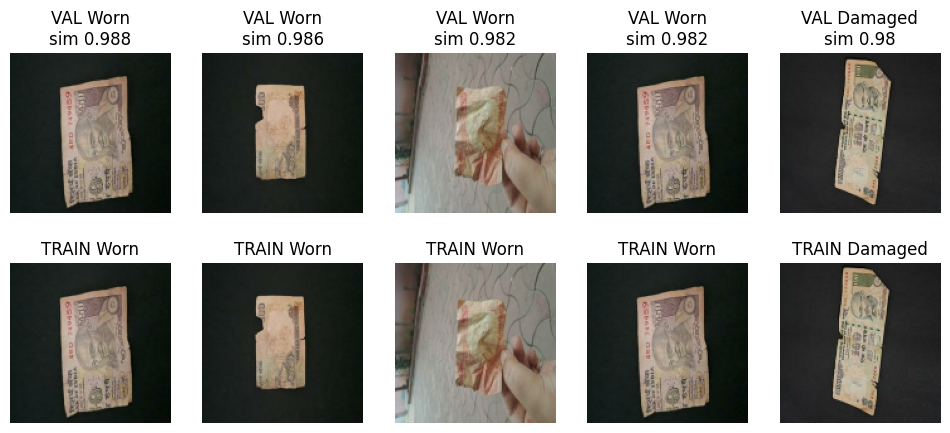

In [ ]:
import matplotlib.pyplot as plt

# Fresh ImageNet MobileNetV2 (not fine-tuned), so similarity is not biased by our labels
fresh_base = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3), include_top=False, weights='imagenet', pooling='avg')
inp = keras.Input(shape=(128, 128, 3))
z = layers.Rescaling(1.0 / 127.5, offset=-1)(inp)
z = fresh_base(z, training=False)
feature_model = keras.Model(inp, z)

# Collect images and labels from a dataset into numpy arrays
def get_images_and_labels(ds):
    images, labels = [], []
    for x, y in ds:
        images.append(x.numpy())
        labels.append(np.argmax(y.numpy(), axis=1))
    return np.concatenate(images), np.concatenate(labels)

train_imgs, train_lbls = get_images_and_labels(train_ds)
val_imgs, val_lbls = get_images_and_labels(val_ds)

# Turn every image into a feature vector, then make each vector length 1
train_feat = feature_model.predict(train_imgs)
val_feat = feature_model.predict(val_imgs)
train_feat = train_feat / np.linalg.norm(train_feat, axis=1, keepdims=True)
val_feat = val_feat / np.linalg.norm(val_feat, axis=1, keepdims=True)

# Cosine similarity of every val image to every train image
similarity = val_feat @ train_feat.T
best_sim = similarity.max(axis=1)
best_idx = similarity.argmax(axis=1)

# Show the 5 val images that look MOST like a train image
top5 = np.argsort(best_sim)[::-1][:5]
plt.figure(figsize=(12, 5))
for k, v in enumerate(top5):
    t = best_idx[v]
    plt.subplot(2, 5, k + 1)
    plt.imshow(val_imgs[v].astype('uint8'))
    plt.title('VAL ' + class_names[val_lbls[v]] + '\nsim ' + str(round(best_sim[v], 3)))
    plt.axis('off')
    plt.subplot(2, 5, k + 6)
    plt.imshow(train_imgs[t].astype('uint8'))
    plt.title('TRAIN ' + class_names[train_lbls[t]])
    plt.axis('off')
plt.show()

how many val images are leaked at each threshold, and accuracy on the rest

In [ ]:
# For each threshold, remove val images whose best train match is above it
for t in [0.97, 0.95, 0.93, 0.90, 0.85]:
    keep = best_sim < t
    removed = len(keep) - keep.sum()
    acc_clean = np.mean(val_pred_mob[keep] == val_true[keep])
    left_per_class = np.bincount(val_true[keep], minlength=3)
    print('threshold', t, '| removed:', removed, '| left:', keep.sum(),
          '| per class:', left_per_class, '| accuracy on rest:', round(acc_clean, 3))

threshold 0.97 | removed: 21 | left: 159 | per class: [57 55 47] | accuracy on rest: 0.981
threshold 0.95 | removed: 75 | left: 105 | per class: [45 38 22] | accuracy on rest: 0.971
threshold 0.93 | removed: 114 | left: 66 | per class: [30 27  9] | accuracy on rest: 0.97
threshold 0.9 | removed: 135 | left: 45 | per class: [13 24  8] | accuracy on rest: 0.956
threshold 0.85 | removed: 150 | left: 30 | per class: [ 9 19  2] | accuracy on rest: 0.967


look at pairs at lower similarity, to see where “same note” stops

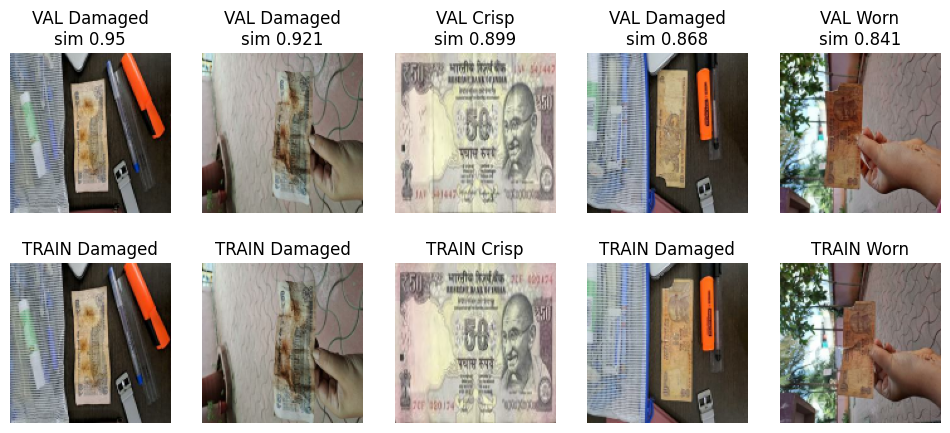

In [ ]:
# Pick val images whose best similarity is closest to each target value
targets = [0.95, 0.92, 0.90, 0.87, 0.84]
plt.figure(figsize=(12, 5))
for k, target in enumerate(targets):
    v = np.argmin(np.abs(best_sim - target))
    t = best_idx[v]
    plt.subplot(2, 5, k + 1)
    plt.imshow(val_imgs[v].astype('uint8'))
    plt.title('VAL ' + class_names[val_lbls[v]] + '\nsim ' + str(round(best_sim[v], 3)))
    plt.axis('off')
    plt.subplot(2, 5, k + 6)
    plt.imshow(train_imgs[t].astype('uint8'))
    plt.title('TRAIN ' + class_names[train_lbls[t]])
    plt.axis('off')
plt.show()

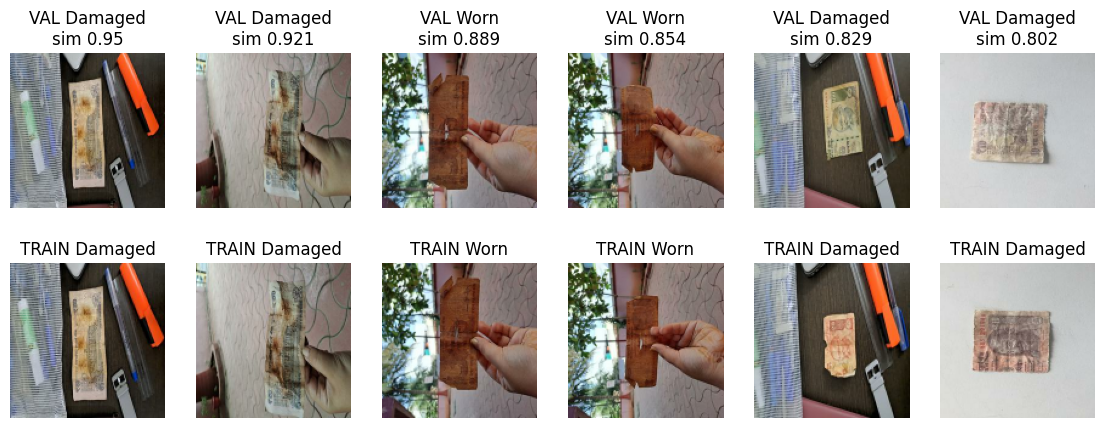

In [ ]:
# Damaged/Worn pairs only, at lower similarity
dw_idx = np.where(val_lbls != 0)[0]
targets = [0.95, 0.92, 0.89, 0.86, 0.83, 0.80]
plt.figure(figsize=(14, 5))
for k, target in enumerate(targets):
    v = dw_idx[np.argmin(np.abs(best_sim[dw_idx] - target))]
    t = best_idx[v]
    plt.subplot(2, 6, k + 1)
    plt.imshow(val_imgs[v].astype('uint8'))
    plt.title('VAL ' + class_names[val_lbls[v]] + '\nsim ' + str(round(best_sim[v], 3)))
    plt.axis('off')
    plt.subplot(2, 6, k + 7)
    plt.imshow(train_imgs[t].astype('uint8'))
    plt.title('TRAIN ' + class_names[train_lbls[t]])
    plt.axis('off')
plt.show()

Possible label conflicts (sim > 0.85): 2


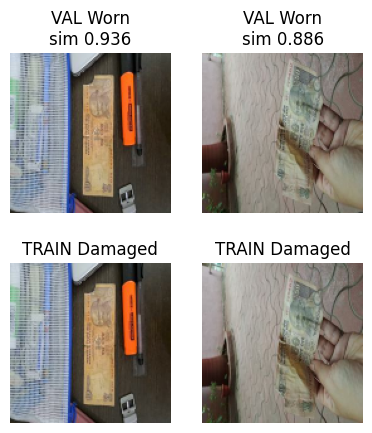

In [ ]:
# Possible label conflicts: very similar val/train images with different labels
conflict = []
for v in dw_idx:
    if best_sim[v] > 0.85 and train_lbls[best_idx[v]] != val_lbls[v]:
        conflict.append(v)
print('Possible label conflicts (sim > 0.85):', len(conflict))

plt.figure(figsize=(12, 5))
for k, v in enumerate(conflict[:5]):
    t = best_idx[v]
    plt.subplot(2, 5, k + 1)
    plt.imshow(val_imgs[v].astype('uint8'))
    plt.title('VAL ' + class_names[val_lbls[v]] + '\nsim ' + str(round(best_sim[v], 3)))
    plt.axis('off')
    plt.subplot(2, 5, k + 6)
    plt.imshow(train_imgs[t].astype('uint8'))
    plt.title('TRAIN ' + class_names[train_lbls[t]])
    plt.axis('off')
plt.show()

class-specific rule: accuracy on clean val images

In [ ]:
# A val image counts as "seen in train" if its closest train image is very similar
# Crisp: 0.97 or more, Damaged/Worn: 0.85 or more (chosen by looking at pairs)
CRISP_LIMIT = 0.97
PHOTO_LIMIT = 0.85

seen = []
for v in range(len(val_lbls)):
    if val_lbls[v] == 0:
        seen.append(best_sim[v] >= CRISP_LIMIT)
    else:
        seen.append(best_sim[v] >= PHOTO_LIMIT)
seen = np.array(seen)
clean = np.logical_not(seen)

# How many val images are left in each class (Crisp, Damaged, Worn)
print('All val per class:         ', np.bincount(val_true, minlength=3))
print('Seen in train per class:   ', np.bincount(val_true[seen], minlength=3))
print('Clean per class:           ', np.bincount(val_true[clean], minlength=3))

# Accuracy on all val images vs only the clean ones, for both models
print('Custom CNN  | all val:', round(np.mean(val_pred == val_true), 3),
      '| clean val:', round(np.mean(val_pred[clean] == val_true[clean]), 3))
print('MobileNetV2 | all val:', round(np.mean(val_pred_mob == val_true), 3),
      '| clean val:', round(np.mean(val_pred_mob[clean] == val_true[clean]), 3))

All val per class:          [60 60 60]
Seen in train per class:    [ 3 41 58]
Clean per class:            [57 19  2]
Custom CNN  | all val: 0.944 | clean val: 0.936
MobileNetV2 | all val: 0.983 | clean val: 0.987


Findings of the leakage check:
- Similarity was measured with ImageNet MobileNetV2 features (not the fine-tuned model).
- Cut-offs chosen by looking at image pairs, not by accuracy: Crisp ≥ 0.97, Damaged/Worn ≥ 0.85.
- 58/60 Worn and 41/60 Damaged val images have a same-note, same-scene photo in train
  (the source dataset has several shots per note).
- 2 val images are the same photo as a train image but with a different label (Worn vs Damaged).
- "Clean val" accuracy is not reported: only 2 Worn and 19 Damaged images were left.
- Conclusion: accuracies are optimistic for unseen notes. Dataset kept as is (no new data available).

# 6.Evaluate both models on the test set

load the best saved models and predict on test

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the best saved version of each model from Drive
cnn_best = keras.models.load_model(PROJECT + '/models/custom_cnn_best.keras')
mob_best = keras.models.load_model(PROJECT + '/models/mobilenet_best.keras')

# True test labels (test_ds is not shuffled, so the order matches the predictions)
test_true = np.concatenate([np.argmax(y.numpy(), axis=1) for x, y in test_ds])

# Predicted class = the class with the highest probability
test_pred_cnn = np.argmax(cnn_best.predict(test_ds), axis=1)
test_pred_mob = np.argmax(mob_best.predict(test_ds), axis=1)

print('Test images:', len(test_true))
print('Custom CNN  test accuracy:', round(accuracy_score(test_true, test_pred_cnn), 3))
print('MobileNetV2 test accuracy:', round(accuracy_score(test_true, test_pred_mob), 3))

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step
Test images: 184
Custom CNN  test accuracy: 0.837
MobileNetV2 test accuracy: 0.989


confusion matrices (saved) and per-class precision/recall/F1

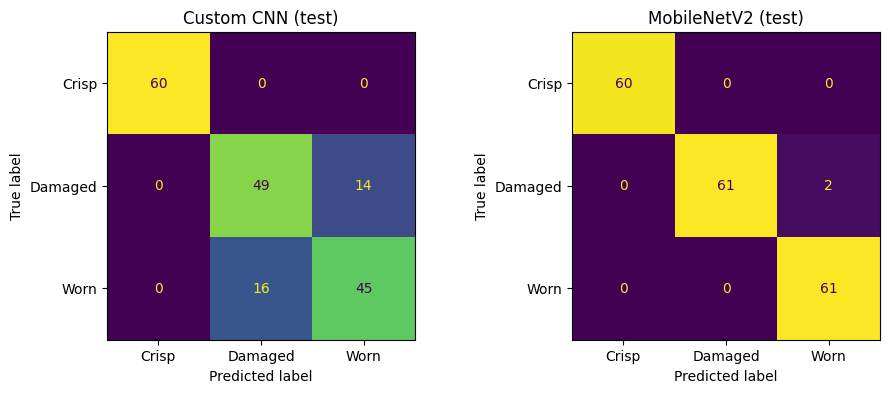

Custom CNN
              precision    recall  f1-score   support

       Crisp      1.000     1.000     1.000        60
     Damaged      0.754     0.778     0.766        63
        Worn      0.763     0.738     0.750        61

    accuracy                          0.837       184
   macro avg      0.839     0.838     0.839       184
weighted avg      0.837     0.837     0.837       184

MobileNetV2
              precision    recall  f1-score   support

       Crisp      1.000     1.000     1.000        60
     Damaged      1.000     0.968     0.984        63
        Worn      0.968     1.000     0.984        61

    accuracy                          0.989       184
   macro avg      0.989     0.989     0.989       184
weighted avg      0.989     0.989     0.989       184



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Draw both confusion matrices side by side (rows = true class, columns = predicted)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_cnn = confusion_matrix(test_true, test_pred_cnn)
ConfusionMatrixDisplay(cm_cnn, display_labels=class_names).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Custom CNN (test)')

cm_mob = confusion_matrix(test_true, test_pred_mob)
ConfusionMatrixDisplay(cm_mob, display_labels=class_names).plot(ax=axes[1], colorbar=False)
axes[1].set_title('MobileNetV2 (test)')

# Save to the results folder, then show
plt.savefig(PROJECT + '/results/confusion_matrices_test.png', dpi=150, bbox_inches='tight')
plt.show()

# Precision, recall and F1 for each class
print('Custom CNN')
print(classification_report(test_true, test_pred_cnn, target_names=class_names, digits=3))
print('MobileNetV2')
print(classification_report(test_true, test_pred_mob, target_names=class_names, digits=3))

comparison table (saved as CSV)

In [ ]:
import pandas as pd
from sklearn.metrics import f1_score

# Damaged/Worn only: the hard pair (Crisp is easy for both models)
dw = test_true != 0

# One row per model: size, overall accuracy, macro F1 and Damaged/Worn accuracy
comparison = pd.DataFrame({
    'Model': ['Custom CNN (from scratch)', 'MobileNetV2 (transfer learning)'],
    'Parameters': [cnn_best.count_params(), mob_best.count_params()],
    'Test accuracy': [round(accuracy_score(test_true, test_pred_cnn), 3),
                      round(accuracy_score(test_true, test_pred_mob), 3)],
    'Macro F1': [round(f1_score(test_true, test_pred_cnn, average='macro'), 3),
                 round(f1_score(test_true, test_pred_mob, average='macro'), 3)],
    'Damaged/Worn accuracy': [round(np.mean(test_pred_cnn[dw] == test_true[dw]), 3),
                              round(np.mean(test_pred_mob[dw] == test_true[dw]), 3)],
})

# Save for the report, then show
comparison.to_csv(PROJECT + '/results/model_comparison.csv', index=False)
print(comparison)

                             Model  Parameters  Test accuracy  Macro F1  \
0        Custom CNN (from scratch)      102595          0.837     0.839   
1  MobileNetV2 (transfer learning)     2261827          0.989     0.989   

   Damaged/Worn accuracy  
0                  0.758  
1                  0.984  


how many test images have a near-copy in train

In [ ]:
# Feature vectors for the test images (same ImageNet model as the leakage check)
test_imgs, test_lbls = get_images_and_labels(test_ds)
test_feat = feature_model.predict(test_imgs)
test_feat = test_feat / np.linalg.norm(test_feat, axis=1, keepdims=True)

# Similarity of each test image to its closest train image
test_best_sim = (test_feat @ train_feat.T).max(axis=1)

# Same cut-offs as on val (Crisp 0.97, Damaged/Worn 0.85), fixed before seeing test results
seen_test = []
for v in range(len(test_lbls)):
    if test_lbls[v] == 0:
        seen_test.append(test_best_sim[v] >= CRISP_LIMIT)
    else:
        seen_test.append(test_best_sim[v] >= PHOTO_LIMIT)
seen_test = np.array(seen_test)

print('Test per class (Crisp, Damaged, Worn):', np.bincount(test_lbls, minlength=3))
print('Seen in train per class:              ', np.bincount(test_lbls[seen_test], minlength=3))

# Accuracy on Damaged/Worn test images that have NO near-copy in train
new_dw = np.logical_and(np.logical_not(seen_test), test_lbls != 0)
print('Damaged/Worn test images with no near-copy in train:', new_dw.sum())
if new_dw.sum() > 0:
    print('Custom CNN  accuracy on them:', round(np.mean(test_pred_cnn[new_dw] == test_lbls[new_dw]), 3))
    print('MobileNetV2 accuracy on them:', round(np.mean(test_pred_mob[new_dw] == test_lbls[new_dw]), 3))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Test per class (Crisp, Damaged, Worn): [60 63 61]
Seen in train per class:               [ 1 33 59]
Damaged/Worn test images with no near-copy in train: 32
Custom CNN  accuracy on them: 0.594
MobileNetV2 accuracy on them: 0.938


Step 6 findings:
- Test accuracy: Custom CNN 83.7% (macro F1 0.839, 102,595 params);
  MobileNetV2 98.9% (macro F1 0.989, 2,261,827 params).
- Crisp is 100% for both models; all errors are Damaged <-> Worn.
- Near-copy check on test (same rule as Step 5b): 59/61 Worn and 33/63 Damaged
  test images have a same-note photo in train.
- On the 32 Damaged/Worn test images with no near-copy (mostly Damaged):
  Custom CNN 59.4%, MobileNetV2 93.8%. Small sample, so indicative only.
- Conclusion: MobileNetV2 generalises much better to unseen notes; the custom CNN
  depends partly on having seen the same note in training.

# 7. Analyse 2 misclassified test images.

find the mistakes and their confidence

In [ ]:
# Probabilities for every test image (needed for the confidence scores)
test_probs_cnn = cnn_best.predict(test_ds)
test_probs_mob = mob_best.predict(test_ds)

# Index numbers of the test images each model got wrong
wrong_cnn = np.where(test_pred_cnn != test_true)[0]
wrong_mob = np.where(test_pred_mob != test_true)[0]
print('Custom CNN wrong:', len(wrong_cnn), '| MobileNetV2 wrong:', len(wrong_mob))

# List every MobileNetV2 mistake
for i in wrong_mob:
    print('MobileNetV2 | image', i,
          '| true:', class_names[test_true[i]],
          '| predicted:', class_names[test_pred_mob[i]],
          '| confidence:', round(test_probs_mob[i].max(), 3),
          '| seen in train:', seen_test[i])

# Custom CNN: the mistake it was most confident about
cnn_confidence = test_probs_cnn[wrong_cnn].max(axis=1)
worst_cnn = wrong_cnn[np.argmax(cnn_confidence)]
print('Custom CNN  | image', worst_cnn,
      '| true:', class_names[test_true[worst_cnn]],
      '| predicted:', class_names[test_pred_cnn[worst_cnn]],
      '| confidence:', round(test_probs_cnn[worst_cnn].max(), 3),
      '| seen in train:', seen_test[worst_cnn])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Custom CNN wrong: 30 | MobileNetV2 wrong: 2
MobileNetV2 | image 77 | true: Damaged | predicted: Worn | confidence: 0.548 | seen in train: False
MobileNetV2 | image 96 | true: Damaged | predicted: Worn | confidence: 0.995 | seen in train: False
Custom CNN  | image 62 | true: Damaged | predicted: Worn | confidence: 0.935 | seen in train: False


show the two images next to their closest training image (saved)

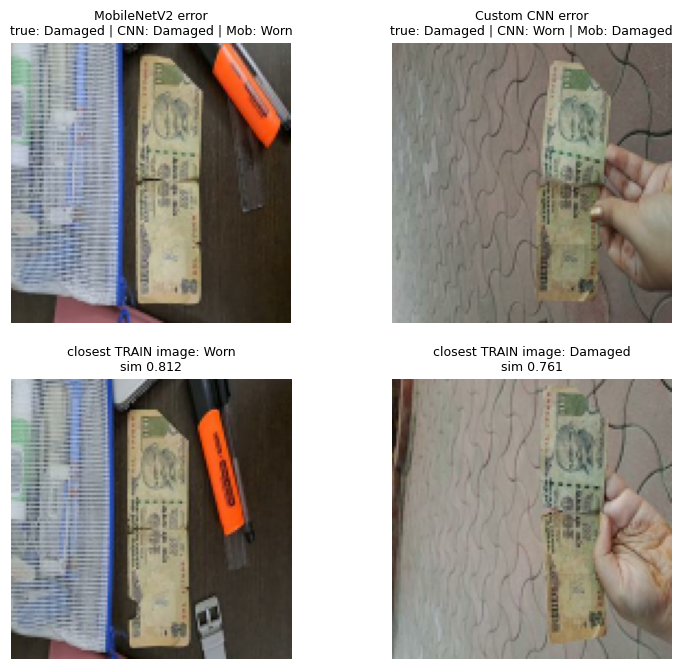

In [ ]:
# The two images we analyse: one MobileNetV2 error and the custom CNN's most confident error
chosen = [wrong_mob[0], worst_cnn]
titles = ['MobileNetV2 error', 'Custom CNN error']

# Closest training image for every test image
test_best_idx = (test_feat @ train_feat.T).argmax(axis=1)

plt.figure(figsize=(9, 8))
for k in range(2):
    i = chosen[k]
    t = test_best_idx[i]

    # Top row: the misclassified test image, with both models' predictions
    plt.subplot(2, 2, k + 1)
    plt.imshow(test_imgs[i].astype('uint8'))
    plt.title(titles[k] + '\ntrue: ' + class_names[test_true[i]]
              + ' | CNN: ' + class_names[test_pred_cnn[i]]
              + ' | Mob: ' + class_names[test_pred_mob[i]], fontsize=9)
    plt.axis('off')

    # Bottom row: its closest training image
    plt.subplot(2, 2, k + 3)
    plt.imshow(train_imgs[t].astype('uint8'))
    plt.title('closest TRAIN image: ' + class_names[train_lbls[t]]
              + '\nsim ' + str(round(test_best_sim[i], 3)), fontsize=9)
    plt.axis('off')

plt.savefig(PROJECT + '/results/misclassified_examples.png', dpi=150, bbox_inches='tight')
plt.show()

Step 7 findings:
- Image 77 (MobileNetV2 error): true Damaged, predicted Worn with low confidence (0.548).
  Its closest training image is the same scene with a very similar note labelled Worn,
  so the error is most likely caused by inconsistent Damaged/Worn labels.
- Image 62 (Custom CNN's most confident error): true Damaged, predicted Worn (0.935).
  The tear is a thin line partly hidden by the fingers and the note is small in the frame;
  at 128x128 the CNN appears to rely on overall faded colour and misses the tear.
  MobileNetV2 classified it correctly.

# 8. Grad-CAM on the custom CNN for ~3 images (one per class if possible).


the Grad-CAM function

In [ ]:
# Name of the last convolution layer (Grad-CAM uses its output)
last_conv_name = None
for layer in cnn_best.layers:
    if isinstance(layer, layers.Conv2D):
        last_conv_name = layer.name
print('Last conv layer:', last_conv_name)

# Grad-CAM: which parts of the image pushed the model towards its predicted class
def gradcam(img):
    x = tf.convert_to_tensor(img[np.newaxis].astype('float32'))
    with tf.GradientTape() as tape:
        # Run the image through the model one layer at a time,
        # keeping the output of the last conv layer
        h = x
        for layer in cnn_best.layers:
            h = layer(h, training=False)
            if layer.name == last_conv_name:
                conv_out = h
        pred_class = int(tf.argmax(h[0]))
        score = h[0, pred_class]

    # How much each conv feature map affects the score of the predicted class
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weighted sum of the feature maps; keep only positive values; scale to 0-1
    cam = tf.reduce_sum(conv_out[0] * weights, axis=-1)
    cam = tf.maximum(cam, 0) / (tf.reduce_max(cam) + 1e-8)

    # Resize the 32x32 map to the 128x128 image size
    heatmap = tf.image.resize(cam[..., tf.newaxis], (128, 128)).numpy()[:, :, 0]
    return heatmap, pred_class

Last conv layer: conv2d_11


choose the images, draw the heatmaps and save

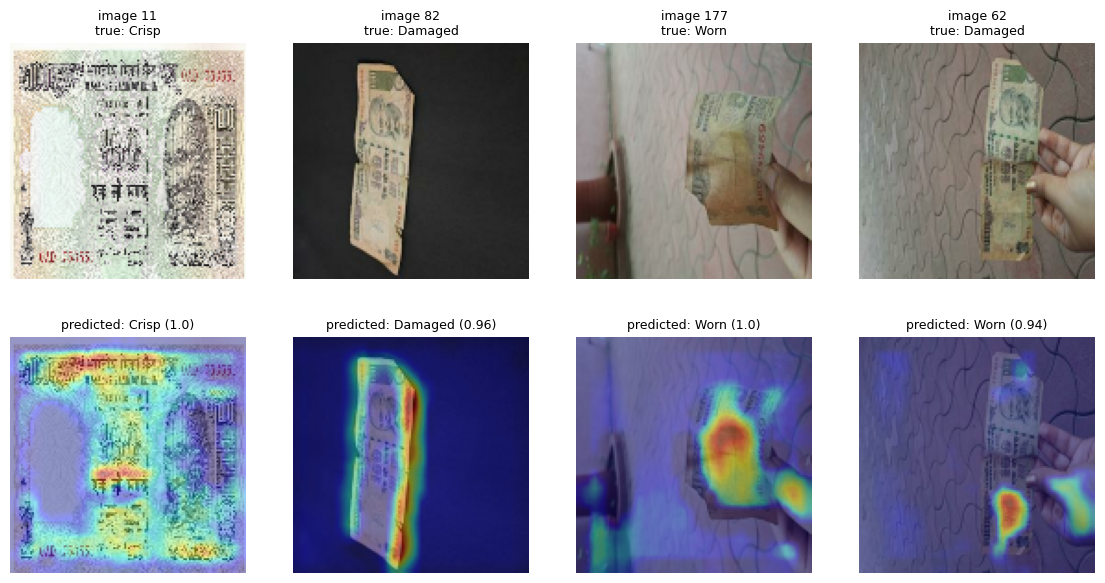

In [ ]:
# One correctly classified test image per class (the one the CNN was most sure about)
chosen = []
for c in range(3):
    correct_c = np.where(np.logical_and(test_true == c, test_pred_cnn == c))[0]
    best = correct_c[np.argmax(test_probs_cnn[correct_c, c])]
    chosen.append(best)

# Plus the CNN's most confident mistake from Step 7 (image 62)
chosen.append(worst_cnn)

plt.figure(figsize=(14, 7))
for k, i in enumerate(chosen):
    heatmap, pred_class = gradcam(test_imgs[i])

    # Top row: the original image
    plt.subplot(2, 4, k + 1)
    plt.imshow(test_imgs[i].astype('uint8'))
    plt.title('image ' + str(i) + '\ntrue: ' + class_names[test_true[i]], fontsize=9)
    plt.axis('off')

    # Bottom row: the heatmap on top of the image (red = most important)
    plt.subplot(2, 4, k + 5)
    plt.imshow(test_imgs[i].astype('uint8'))
    plt.imshow(heatmap, cmap='jet', alpha=0.4)
    plt.title('predicted: ' + class_names[pred_class]
              + ' (' + str(round(test_probs_cnn[i].max(), 2)) + ')', fontsize=9)
    plt.axis('off')

plt.savefig(PROJECT + '/results/gradcam_custom_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Show the file path of the 3 test images used in Grad-CAM
for i in [11, 82, 177]:
    print(i, class_names[test_true[i]], test_ds.file_paths[i])

11 Crisp /content/drive/MyDrive/Dataset_v2/test/Crisp/100_097.jpg
82 Damaged /content/drive/MyDrive/Dataset_v2/test/Damaged/100_093.jpg
177 Worn /content/drive/MyDrive/Dataset_v2/test/Worn/50_025.jpg


Step 8 findings (Grad-CAM on the custom CNN, last conv layer):
- Damaged (image 82): attention on the note's edges and bent corner; background ignored.
- Worn (image 177): attention mainly on the faded centre of the note, some on the hand.
- Crisp (image 11): weak attention spread over the whole scan; since the note fills the
  frame, Grad-CAM cannot separate real crispness from the clean-scan capture style.
- Misclassified Damaged (image 62, predicted Worn): attention on the fingers/hand,
  not on the tear. The CNN appears to partly link hand-held photos with Worn.
- Conclusion: the CNN mostly uses the note for clear cases but also relies partly on
  capture-style cues (hands, scan style). Only 4 images were checked.

# 9. Demo — see currency_demo.ipynb in the same folder